# Q1: Image Transformations

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt
from google.colab import files
plt.rcParams['figure.dpi'] = 100

def show(img, title="", ax=None, grid=False):
    ax = ax or plt.gca()
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    if grid: ax.grid(True, alpha=0.4)
    else: ax.axis('off')

def to3(M):
    # 2x3 affine matrix -> 3x3 homogeneous matrix
    return np.vstack([M, [0, 0, 1]]).astype(np.float64)

Saving pexels-optical-chemist-340351297-31256342.jpg to pexels-optical-chemist-340351297-31256342.jpg


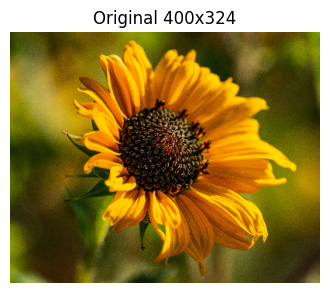

In [2]:
img = None
try:
    up = files.upload()
    if up:
        img = cv2.imread(list(up.keys())[0])
except Exception as e:
    print("No upload:", e)

if img is None:
    from skimage import data
    img = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
    print("Using sample image")

# resize to a manageable size
scale = 400 / max(img.shape[:2])
img = cv2.resize(img, None, fx=scale, fy=scale)
h, w = img.shape[:2]
plt.figure(figsize=(4,4)); show(img, f"Original {w}x{h}"); plt.show()

## (a) 2D transformations: translation, rotation, scaling, shearing
Each is a 3x3 matrix applied to pixel coordinates. All results are drawn on a larger canvas with axes so you can see the **position and shape** change.

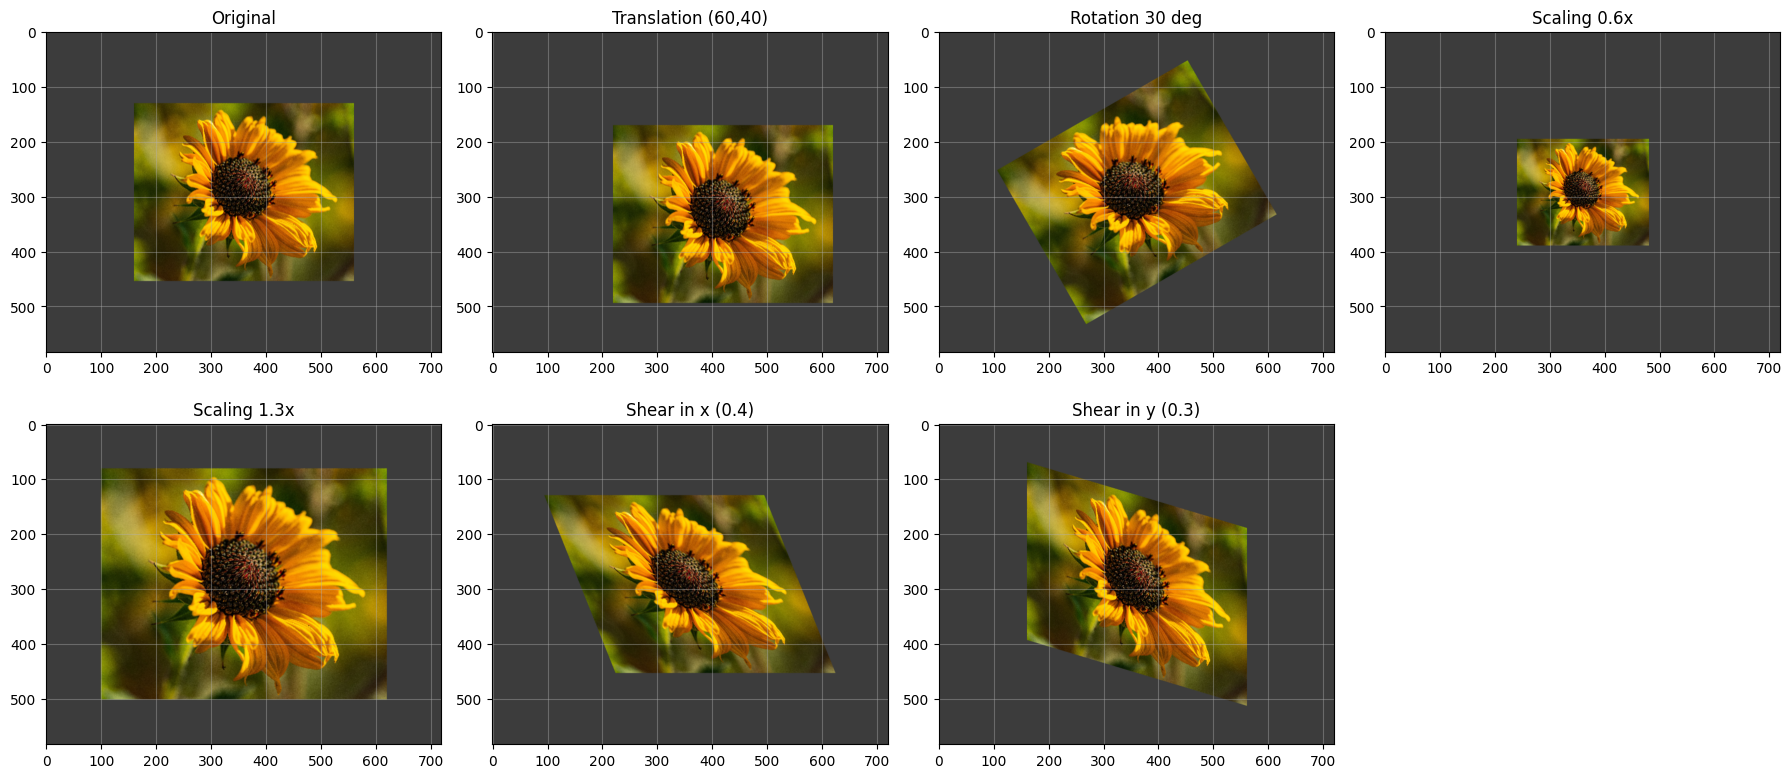

In [3]:
margin = 0.4
W2, H2 = int(w*(1+2*margin)), int(h*(1+2*margin))
T0 = np.array([[1,0,margin*w],[0,1,margin*h],[0,0,1]], float)   # puts the image in the middle of the canvas

def apply(M3):
    return cv2.warpAffine(img, (T0 @ M3)[:2], (W2, H2), borderValue=(60,60,60))

cx, cy = w/2, h/2
transforms = {
 "Original":            np.eye(3),
 "Translation (60,40)": np.array([[1,0,60],[0,1,40],[0,0,1]], float),
 "Rotation 30 deg":     to3(cv2.getRotationMatrix2D((cx,cy), 30, 1.0)),
 "Scaling 0.6x":        to3(cv2.getRotationMatrix2D((cx,cy), 0, 0.6)),
 "Scaling 1.3x":        to3(cv2.getRotationMatrix2D((cx,cy), 0, 1.3)),
 "Shear in x (0.4)":    np.array([[1,0.4,-0.4*cy],[0,1,0],[0,0,1]], float),
 "Shear in y (0.3)":    np.array([[1,0,0],[0.3,1,-0.3*cx],[0,0,1]], float),
}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, M) in zip(axes.ravel(), transforms.items()):
    show(apply(M), name, ax, grid=True)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**Observation:** translation only moves the image; rotation turns it (shape/size preserved); scaling changes size; shearing slants it so rectangles become parallelograms (angles change, but the image is still a flat 2D shape).

## (b) 3D transformation (cube rotated / moved along x, y, z)
A cube is rotated about each axis and translated along x, y, z using 4x4 homogeneous matrices.

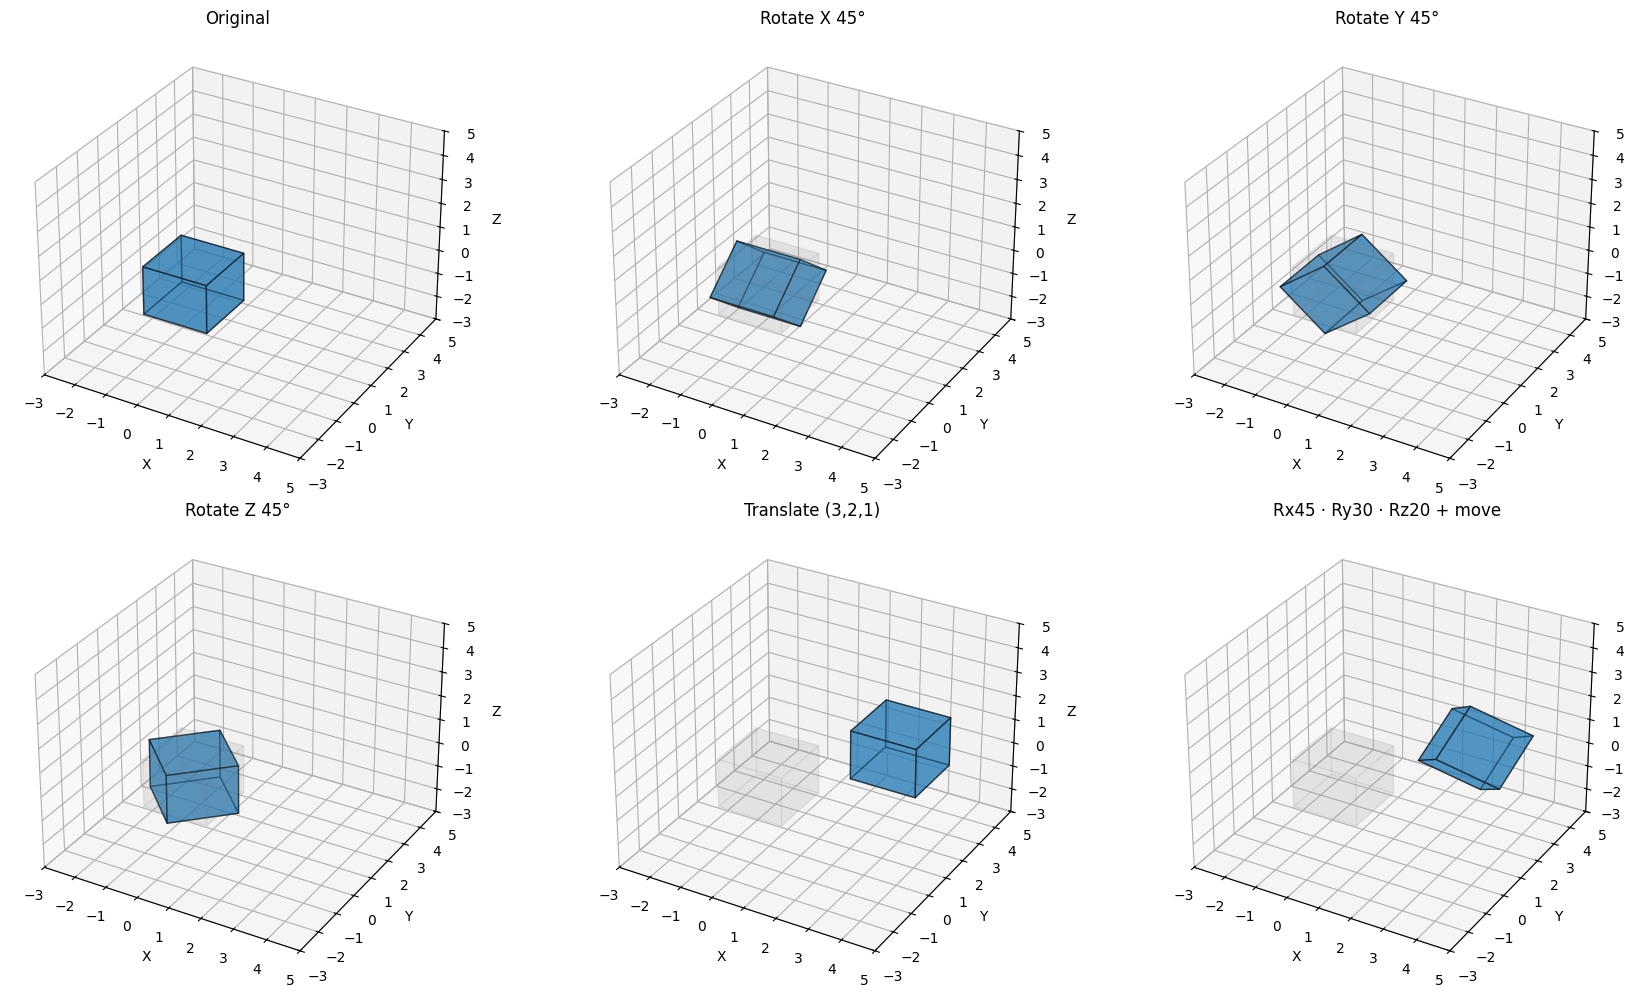

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

V = np.array([[x,y,z] for x in (-1,1) for y in (-1,1) for z in (-1,1)], float)
faces_idx = [[0,1,3,2],[4,5,7,6],[0,1,5,4],[2,3,7,6],[0,2,6,4],[1,3,7,5]]

def Rx(a): a=np.radians(a); return np.array([[1,0,0,0],[0,np.cos(a),-np.sin(a),0],[0,np.sin(a),np.cos(a),0],[0,0,0,1]])
def Ry(a): a=np.radians(a); return np.array([[np.cos(a),0,np.sin(a),0],[0,1,0,0],[-np.sin(a),0,np.cos(a),0],[0,0,0,1]])
def Rz(a): a=np.radians(a); return np.array([[np.cos(a),-np.sin(a),0,0],[np.sin(a),np.cos(a),0,0],[0,0,1,0],[0,0,0,1]])
def Tr(tx,ty,tz): M=np.eye(4); M[:3,3]=[tx,ty,tz]; return M

def transform(M):
    Vh = np.hstack([V, np.ones((8,1))])
    return (M @ Vh.T).T[:, :3]

cases = {
 "Original": np.eye(4),
 "Rotate X 45°": Rx(45),
 "Rotate Y 45°": Ry(45),
 "Rotate Z 45°": Rz(45),
 "Translate (3,2,1)": Tr(3,2,1),
 "Rx45 · Ry30 · Rz20 + move": Tr(3,2,1) @ Rz(20) @ Ry(30) @ Rx(45),
}
fig = plt.figure(figsize=(18,10))
for i,(name,M) in enumerate(cases.items(),1):
    ax = fig.add_subplot(2,3,i, projection='3d')
    ref = transform(np.eye(4))
    ax.add_collection3d(Poly3DCollection([ref[f] for f in faces_idx], alpha=0.08, facecolor='gray', edgecolor='gray'))
    P = transform(M)
    ax.add_collection3d(Poly3DCollection([P[f] for f in faces_idx], alpha=0.5, facecolor='tab:blue', edgecolor='k'))
    ax.set_xlim(-3,5); ax.set_ylim(-3,5); ax.set_zlim(-3,5)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z'); ax.set_title(name)
plt.tight_layout(); plt.show()

## (c) Homogeneous coordinates
A 2D point (x, y) is written as **(x, y, 1)**. In general (x, y, w) represents the point (x/w, y/w).

**Why the extra coordinate?**
1. A 2x2 matrix can do rotation, scaling and shear, but **cannot do translation** (it is an addition, not a multiplication).
2. With the extra coordinate, translation becomes a matrix multiplication, so **all transforms are 3x3 matrices** and can be **combined by multiplying matrices** (one matrix for a whole pipeline).
3. It lets us represent **projective transforms** (perspective) and points at infinity (w = 0), which is essential in camera models and homography in computer vision.

Point: [4 3]  -> homogeneous: [4 3 1]
Translated: [6. 8. 1.]
Rotated   : [-3.  4.  1.]
Scaled    : [8. 6. 1.]
Combined matrix:
 [[ 0. -2.  2.]
 [ 2.  0.  5.]
 [ 0.  0.  1.]]
Combined result (x,y): [-4. 13.]
(8,6,2) -> [4. 3.]


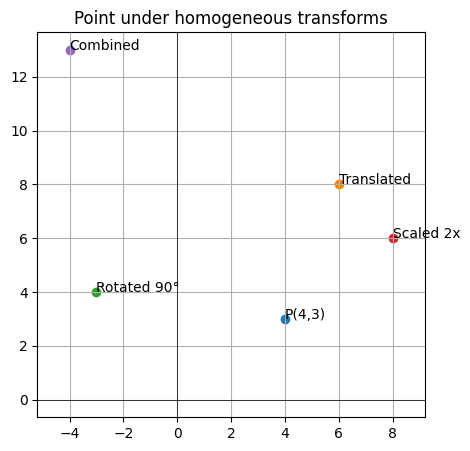

In [5]:
p = np.array([4, 3])
ph = np.array([4, 3, 1])
print("Point:", p, " -> homogeneous:", ph)

T = np.array([[1,0,2],[0,1,5],[0,0,1]], float)                  # translate by (2,5)
th = np.radians(90)
R = np.array([[np.cos(th),-np.sin(th),0],[np.sin(th),np.cos(th),0],[0,0,1]])   # rotate 90 deg
S = np.diag([2,2,1.0])                                          # scale 2x

print("Translated:", T @ ph)
print("Rotated   :", np.round(R @ ph, 3))
print("Scaled    :", S @ ph)

M = T @ R @ S                                                    # one combined matrix: scale -> rotate -> translate
res = M @ ph
print("Combined matrix:\n", np.round(M,3))
print("Combined result (x,y):", np.round(res[:2]/res[2],3))

# scale invariance: (8,6,2) is the same point as (4,3,1)
q = np.array([8,6,2]); print("(8,6,2) ->", q[:2]/q[2])

plt.figure(figsize=(5,5))
for pt,lab in [(p,'P(4,3)'), ((T@ph)[:2],'Translated'), ((R@ph)[:2],'Rotated 90°'), ((S@ph)[:2],'Scaled 2x'), (res[:2],'Combined')]:
    plt.scatter(*pt); plt.annotate(lab, pt)
plt.axhline(0,c='k',lw=.5); plt.axvline(0,c='k',lw=.5); plt.grid(True); plt.axis('equal'); plt.title("Point under homogeneous transforms"); plt.show()

## (d) Affine transformation
An affine transform (6 DOF) is defined by 3 point pairs. A green grid is drawn on the image first, so we can check whether **straight lines stay straight** (and parallel lines stay parallel).

Affine matrix:
 [[ 0.70175439  0.18575851 60.        ]
 [-0.12180452  0.75232193 64.80000305]]


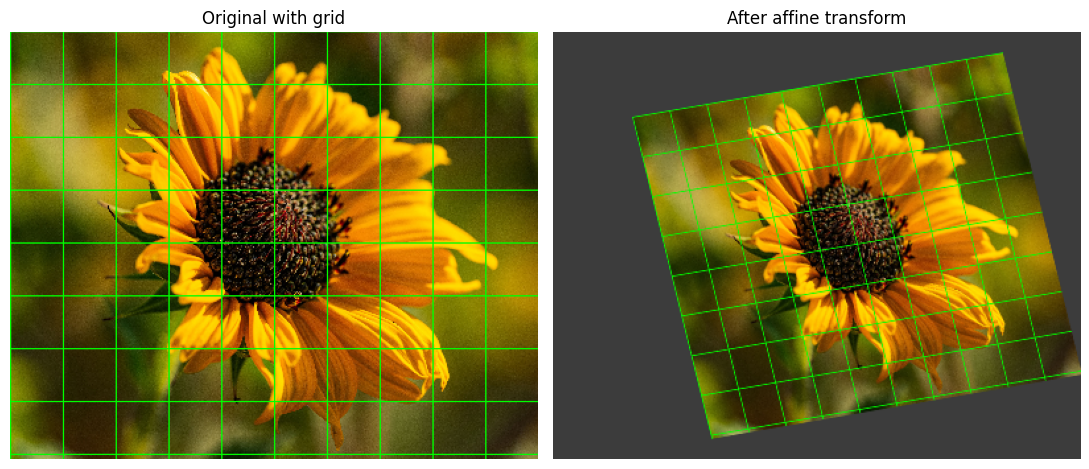

Parallel lines still parallel? cross product = -0.0 -> True
Mid-point still on the same line? cross = 0.0 -> True


In [6]:
grid_img = img.copy()
for x in range(0, w, 40): cv2.line(grid_img, (x,0), (x,h-1), (0,255,0), 1)
for y in range(0, h, 40): cv2.line(grid_img, (0,y), (w-1,y), (0,255,0), 1)

src = np.float32([[0,0],[w-1,0],[0,h-1]])
dst = np.float32([[0.15*w,0.2*h],[0.85*w,0.05*h],[0.3*w,0.95*h]])
A = cv2.getAffineTransform(src, dst)
print("Affine matrix:\n", A)
aff = cv2.warpAffine(grid_img, A, (w, h), borderValue=(60,60,60))

fig, ax = plt.subplots(1,2, figsize=(11,5))
show(grid_img, "Original with grid", ax[0]); show(aff, "After affine transform", ax[1])
plt.tight_layout(); plt.show()

# numerical check: two parallel lines (horizontal) before/after
def tf(pt): v = A @ np.array([pt[0],pt[1],1.0]); return v
l1 = (tf((0,10)), tf((w-1,10)));  l2 = (tf((0,100)), tf((w-1,100)))
d1, d2 = l1[1]-l1[0], l2[1]-l2[0]
cross = d1[0]*d2[1]-d1[1]*d2[0]
mid = tf((w/2,10))
collinear = (l1[1]-l1[0])[0]*(mid-l1[0])[1]-(l1[1]-l1[0])[1]*(mid-l1[0])[0]
print("Parallel lines still parallel? cross product =", round(cross,6), "->", abs(cross)<1e-6)
print("Mid-point still on the same line? cross =", round(collinear,6), "->", abs(collinear)<1e-6)

## (e) Projective transformation (homography): make a slanted book look flat


Saving Screenshot 2026-10-15 143256.png to Screenshot 2026-10-15 143256 (1).png


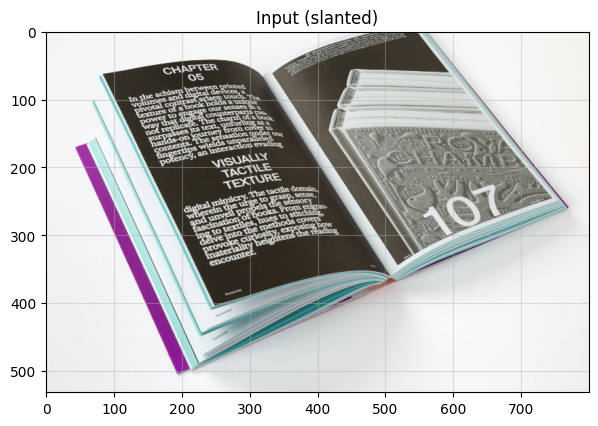

In [13]:
book = None
try:
    up2 = files.upload()
    if up2:
        book = cv2.imread(list(up2.keys())[0])
except Exception as e:
    print("No upload:", e)

if book is None:
    # synthetic slanted "book" if nothing uploaded
    flat = np.full((300,220,3), (230,230,230), np.uint8)
    cv2.rectangle(flat,(0,0),(219,299),(20,60,160),8)
    cv2.putText(flat,"COMPUTER",(25,110),cv2.FONT_HERSHEY_SIMPLEX,0.9,(0,0,0),2)
    cv2.putText(flat,"VISION",(45,160),cv2.FONT_HERSHEY_SIMPLEX,1.1,(0,0,200),3)
    s = np.float32([[0,0],[219,0],[219,299],[0,299]])
    d = np.float32([[120,60],[400,20],[430,330],[90,380]])
    book = np.full((420,520,3), 40, np.uint8)
    mask = cv2.warpPerspective(np.full_like(flat,255), cv2.getPerspectiveTransform(s,d), (520,420))
    warped = cv2.warpPerspective(flat, cv2.getPerspectiveTransform(s,d), (520,420))
    book = np.where(mask>0, warped, book)
    print("Using synthetic slanted book")

sc = 800 / max(book.shape[:2])
if sc < 1: book = cv2.resize(book, None, fx=sc, fy=sc)
plt.figure(figsize=(7,6)); show(book, "Input (slanted)", grid=True); plt.axis('on'); plt.show()

Corners (TL,TR,BR,BL):
 [[ 90.  60.]
 [550.   0.]
 [760. 260.]
 [240. 410.]]
Homography matrix H:
 [[ 9.306400e-01 -3.988500e-01 -5.982701e+01]
 [ 1.732100e-01  1.327940e+00 -9.526559e+01]
 [-3.000000e-04  8.900000e-04  1.000000e+00]]


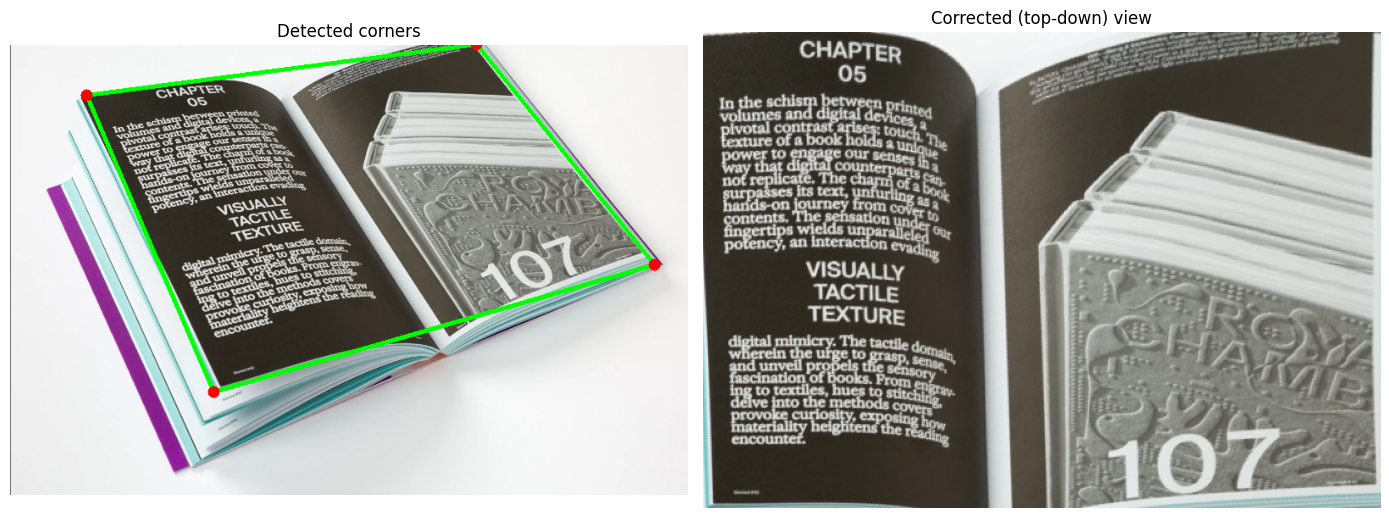

True

In [15]:
MANUAL_PTS = [[90, 60], [550, 0], [760, 260], [240, 410]]   # in order: top-left, top-right, bottom-right, bottom-left

def order_points(pts):
    pts = np.array(pts, dtype=np.float32).reshape(4,2)
    s = pts.sum(1); d = np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def detect_quad(image):
    g = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (5,5), 0)
    for edges in (cv2.Canny(g,50,150), cv2.threshold(g,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)[1]):
        edges = cv2.dilate(edges, np.ones((3,3),np.uint8))
        cnts,_ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:5]:
            ap = cv2.approxPolyDP(c, 0.02*cv2.arcLength(c,True), True)
            if len(ap)==4 and cv2.contourArea(ap) > 0.1*image.shape[0]*image.shape[1]:
                return order_points(ap)
    return None

pts = order_points(MANUAL_PTS) if MANUAL_PTS is not None else detect_quad(book)
if pts is None:
    raise SystemExit("Auto-detect failed: set MANUAL_PTS above using the gridded image.")
print("Corners (TL,TR,BR,BL):\n", pts)

tl,tr,br,bl = pts
outW = int(max(np.linalg.norm(br-bl), np.linalg.norm(tr-tl)))
outH = int(max(np.linalg.norm(tr-br), np.linalg.norm(tl-bl)))
dst = np.float32([[0,0],[outW-1,0],[outW-1,outH-1],[0,outH-1]])

H = cv2.getPerspectiveTransform(pts, dst)
print("Homography matrix H:\n", np.round(H,5))
flat = cv2.warpPerspective(book, H, (outW, outH))

marked = book.copy()
cv2.polylines(marked, [pts.astype(int)], True, (0,255,0), 3)
for p_ in pts.astype(int): cv2.circle(marked, tuple(p_), 7, (0,0,255), -1)

fig, ax = plt.subplots(1,2, figsize=(14,6))
show(marked, "Detected corners", ax[0]); show(flat, "Corrected (top-down) view", ax[1])
plt.tight_layout(); plt.show()
cv2.imwrite("corrected.png", flat)